# PSet #3 · Notebook 05 — Selección del ganador y Model Registry

**Secuencia:** 01 EDA → 02 Features → 03 Baselines → 04 Tuning → **05 Selección** → 06 Verificación.

**Protecciones:**
1. Cargamos exactamente la misma OBT, hash y partición del notebook 03.
2. Seleccionamos umbrales con predicciones *out-of-fold* **solo en train** y costos *hipotéticos*.
3. Fijamos la regla de selección antes de evaluar el **test por primera vez**.
4. Evaluamos **una sola vez** los dos finalistas en test y registramos ambos, con `champion` y `challenger`.
5. El notebook 06 verifica de manera independiente el artefacto del registry.

**Limitación:** la fuente es transversal y no permite demostrar retención causada por campañas; los costos y su eficacia son supuestos de un escenario académico.

In [1]:
from pathlib import Path
import json, os, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, precision_score, recall_score,
                             roc_auc_score, f1_score, confusion_matrix)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
import mlflow
import mlflow.sklearn
from src.datos import leer_obt, variables_modelo, hash_snapshot, ORIGEN
from src.tuning import definiciones_modelos, EXPERIMENTO, SEED
from src.seleccion import parsear_parametros, puntaje_costo, elegir_umbral_oof

OUT = Path('/workspace/docs'); OUT.mkdir(parents=True, exist_ok=True)
REGISTRO = 'PSet3_Churn_Telco-modelo'
TRACKING_URI = os.environ.get('MLFLOW_TRACKING_URI','http://mlflow:5000')
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENTO)
COSTO_CONTACTO = 5.0       # USD por contacto, SUPUESTO
COSTO_ABANDONO = 120.0      # USD por abandono, SUPUESTO
EFICACIA = 0.20            # proporción hipotéticamente retenida, NO medida
print('Tracking:', TRACKING_URI, '| Registro:', REGISTRO)

Tracking: http://mlflow:5000 | Registro: PSet3_Churn_Telco-modelo


## A. Reutilizar exactamente el split original

La partición y el hash se conservaron en `docs/split_train_test.csv` y `docs/split_info.json`. El test **no será inspeccionado** hasta la sección D.

In [2]:
df = leer_obt().sort_values('CUSTOMER_ID', kind='stable').reset_index(drop=True)
info = json.loads((OUT/'split_info.json').read_text(encoding='utf-8'))
assert info['origen'] == ORIGEN and info['hash_dataset'] == hash_snapshot(df)
assert int(info['seed']) == SEED
X, y = variables_modelo(df)
idx_train, idx_test = train_test_split(
    np.arange(len(df)), test_size=.20, random_state=SEED, stratify=y
)
idx_train, idx_test = np.sort(idx_train), np.sort(idx_test)
manifest = pd.read_csv(OUT/'split_train_test.csv', dtype={'CUSTOMER_ID':str})
assert df['CUSTOMER_ID'].astype(str).tolist() == manifest['CUSTOMER_ID'].tolist()
assert (manifest.iloc[idx_train]['split'] == 'train').all()
assert (manifest.iloc[idx_test]['split'] == 'test').all()
assert not set(idx_train).intersection(idx_test)
assert len(idx_train) == 5634 and len(idx_test) == 1409
X_train, y_train = X.iloc[idx_train].copy(), y.iloc[idx_train].copy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
resumen = pd.read_csv(OUT/'resultados_tuning.csv').sort_values('tuned_ap', ascending=False)
assert len(resumen) == 3 and int(resumen['num_config'].sum()) == 90
finalistas = resumen.head(2).copy().reset_index(drop=True)
assert set(finalistas['nombre']) == {'Candidato_HistGradientBoosting', 'Candidato_Logistica'}
print('Snapshot SHA256:', info['hash_dataset'])
print('Train:',len(idx_train),'| Test reservado:',len(idx_test), '| finalistas:',finalistas['nombre'].tolist())
display(finalistas[['nombre','tuned_ap','tuned_std','brecha_train_cv','mejora_supera_variabilidad']].round(5))

Snapshot SHA256: d394e39192c935f813db937647ea608341131d5b3021696fbbb186daff7043d3
Train: 5634 | Test reservado: 1409 | finalistas: ['Candidato_HistGradientBoosting', 'Candidato_Logistica']


,nombre,tuned_ap,tuned_std,brecha_train_cv,mejora_supera_variabilidad
0,Candidato_HistGradientBoosting,0.66907,0.01721,0.04438,False
1,Candidato_Logistica,0.65379,0.01132,0.00837,False


## B. Reconstruir los modelos ajustados desde los mejores parámetros registrados

Se usa la misma implementación de `src/tuning.py` y la misma semilla del notebook 04. Esto permite reproducir los modelos **sin leer test**.

In [3]:
catalogo = definiciones_modelos(SEED)
modelos_sin_fit = {}
for row in finalistas.itertuples(index=False):
    parametros = parsear_parametros(row.best_params_json)
    estimator = clone(catalogo[row.nombre]['estimador']).set_params(**parametros)
    modelos_sin_fit[row.nombre] = estimator
    print(row.nombre, 'parámetros:', parametros)

Candidato_HistGradientBoosting parámetros: {'modelo__l2_regularization': 1.1008110571039521e-05, 'modelo__learning_rate': 0.05681142678077596, 'modelo__max_depth': 3, 'modelo__max_iter': 121, 'modelo__max_leaf_nodes': 39, 'modelo__min_samples_leaf': 60}
Candidato_Logistica parámetros: {'modelo__C': 73.92266140516048, 'modelo__class_weight': None, 'modelo__tol': 0.00023345864076016249}


## C. Selección de umbral y candidato **solo con TRAIN**

Costo ilustrativo por 100 clientes:

\[C=\frac{100}{N}\left(5\,N_{contactados}+120\,(FN+0.8\,TP)\right)\]

Se supone, **sin evidencia causal**, que contactar a un verdadero futuro abandono evitaría el 20% de esas pérdidas. No son costos observados de una empresa.

Calculamos probabilidades *out-of-fold* sobre train para cada finalista, probamos umbrales prefijados de 0,05 a 0,95 y elegimos el mínimo costo esperado. El test sigue reservado.

Generando probabilidades fuera de fold: Candidato_HistGradientBoosting
Generando probabilidades fuera de fold: Candidato_Logistica


,nombre,oof_ap,umbral,costo_oof_por100,contactados_oof,ahorro_oof_ilustrativo_por100
0,Candidato_HistGradientBoosting,0.6661,0.24,2870.2875,2448,313.9510
1,Candidato_Logistica,0.6518,0.20,2874.2989,2738,309.9397


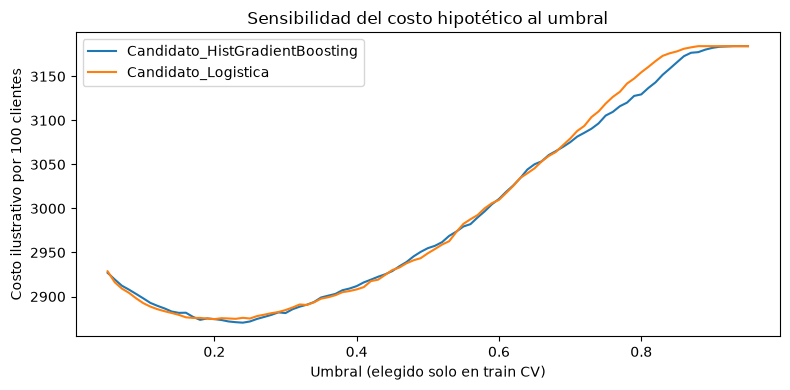

In [4]:
from sklearn.metrics import average_precision_score
filas_oof = []
curvas_costos = {}
for nombre, modelo in modelos_sin_fit.items():
    print('Generando probabilidades fuera de fold:',nombre,flush=True)
    # Se ajusta preprocessing + modelo en cada fold SOLO con train de ese fold.
    oof = cross_val_predict(modelo, X_train, y_train, cv=folds,
                            method='predict_proba', n_jobs=1)[:,1]
    assert len(oof) == len(y_train) and np.isfinite(oof).all()
    mejor, curva = elegir_umbral_oof(y_train, oof,
         costo_contacto=COSTO_CONTACTO, costo_abandono=COSTO_ABANDONO,
         eficacia_hipotetica=EFICACIA)
    curvas_costos[nombre] = pd.DataFrame(curva)
    filas_oof.append({'nombre':nombre, 'oof_ap':average_precision_score(y_train,oof),
         'umbral':mejor['threshold'], 'costo_oof_por100':mejor['cost_per100'],
         'contactados_oof':mejor['contactados'],
         'ahorro_oof_ilustrativo_por100':mejor['ahorro_ilustrativo_per100']})
oof_tabla = pd.DataFrame(filas_oof)
display(oof_tabla.round(4))
oof_tabla.to_csv(OUT/'umbrales_oof.csv', index=False)
fig, ax = plt.subplots(figsize=(8,4))
for nombre, tabla in curvas_costos.items():
    ax.plot(tabla['threshold'], tabla['cost_per100'], label=nombre)
ax.set(xlabel='Umbral (elegido solo en train CV)', ylabel='Costo ilustrativo por 100 clientes',
       title='Sensibilidad del costo hipotético al umbral')
ax.legend(); plt.tight_layout(); plt.savefig(OUT/'costos_por_umbral_oof.png', dpi=160); plt.show()

### Regla fijada **antes** de abrir test

- Si la diferencia de AP medio de CV excede la mayor desviación entre folds, priorizamos AP.
- Si **no** la excede, priorizamos menor costo **OOF en train**. Si los costos están separados por menos del 1%, preferimos la regresión logística por simplicidad y explicabilidad.
- Registramos el criterio y **no usamos test para modificar umbrales o elegir features**.

In [5]:
primera, segunda = finalistas.iloc[0], finalistas.iloc[1]
diferencia = abs(float(primera.tuned_ap) - float(segunda.tuned_ap))
variacion = max(float(primera.tuned_std), float(segunda.tuned_std))
if diferencia > variacion:
    elegido = primera.nombre
    justificacion = 'Ventaja AP CV supera la mayor desviación entre folds'
else:
    orden_costos = oof_tabla.sort_values('costo_oof_por100')
    barato, caro = orden_costos.iloc[0], orden_costos.iloc[1]
    mejora_relativa = (float(caro.costo_oof_por100) - float(barato.costo_oof_por100)) / max(float(caro.costo_oof_por100), 1e-12)
    if mejora_relativa <= 0.01:
        elegido = 'Candidato_Logistica'
        justificacion = 'AP dentro de variabilidad y costo OOF similar (<1%): prevalece explicabilidad'
    else:
        elegido = barato.nombre
        justificacion = 'AP dentro de variabilidad; menor costo hipotético OOF en train'
segundo = next(n for n in modelos_sin_fit if n != elegido)
seleccion_pretest = {
 'champion_propuesto': elegido, 'challenger_propuesto': segundo,
 'criterio': justificacion, 'delta_ap_cv':diferencia, 'max_std_cv':variacion,
 'costos_son_hipoteticos':True,
 'nota': 'decisión y umbrales fijados ANTES de usar test'
}
(OUT/'seleccion_pretest.json').write_text(json.dumps(seleccion_pretest, indent=2,ensure_ascii=False), encoding='utf-8')
print('CAMPEÓN PRESELECCIONADO SIN TEST:', elegido)
print('CHALLENGER:',segundo)
print('Criterio:',justificacion)

CAMPEÓN PRESELECCIONADO SIN TEST: Candidato_Logistica
CHALLENGER: Candidato_HistGradientBoosting
Criterio: AP dentro de variabilidad y costo OOF similar (<1%): prevalece explicabilidad


## D. Única evaluación del conjunto de prueba (hold-out)

**A partir de aquí se utiliza el hold-out por primera vez.** Los umbrales ya están fijados en `docs/umbrales_oof.csv`. Evaluamos ambos modelos una sola vez con **exactamente** la preparación registrada y sin tocar las features, parámetros ni decisiones tras ver los resultados.

,nombre,umbral_oof,test_ap,test_roc_auc,test_precision,test_recall,test_f1,test_costo_simulado_por100,test_ahorro_ilustrativo_por100,test_tp,test_fp,test_fn,test_tn,train_seconds,inference_ms_por_cliente
0,Candidato_HistGradientBoosting,0.24,0.66844,0.84747,0.51227,0.83690,0.63553,2868.91412,316.32363,313,298,61,737,0.15145,0.01002
1,Candidato_Logistica,0.20,0.66142,0.84252,0.46423,0.85027,0.60057,2886.65720,298.58055,318,367,56,668,0.04706,0.00893


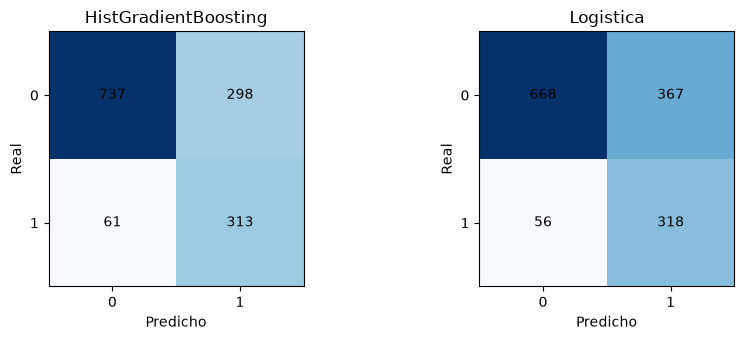

In [6]:
X_test, y_test = X.iloc[idx_test].copy(), y.iloc[idx_test].copy()
filas_test, modelos_fit = [], {}
for nombre, est in modelos_sin_fit.items():
    modelo = clone(est)
    t0 = time.perf_counter(); modelo.fit(X_train, y_train)
    train_secs = time.perf_counter()-t0
    t1 = time.perf_counter(); scores = modelo.predict_proba(X_test)[:,1]
    inf_secs = time.perf_counter()-t1
    umbral = float(oof_tabla.set_index('nombre').loc[nombre,'umbral'])
    pred = (scores >= umbral).astype(int)
    costos = puntaje_costo(y_test, scores, umbral,
         costo_contacto=COSTO_CONTACTO, costo_abandono=COSTO_ABANDONO,
         eficacia_hipotetica=EFICACIA)
    fila = {
        'nombre':nombre, 'umbral_oof':umbral,
        'test_ap':average_precision_score(y_test,scores),
        'test_roc_auc':roc_auc_score(y_test,scores),
        'test_precision':precision_score(y_test,pred,zero_division=0),
        'test_recall':recall_score(y_test,pred,zero_division=0),
        'test_f1':f1_score(y_test,pred,zero_division=0),
        'test_costo_simulado_por100':costos['cost_per100'],
        'test_ahorro_ilustrativo_por100':costos['ahorro_ilustrativo_per100'],
        'test_tp':costos['tp'],'test_fp':costos['fp'],
        'test_fn':costos['fn'],'test_tn':costos['tn'],
        'train_seconds':train_secs, 'inference_ms_por_cliente':1000*inf_secs/len(X_test),
    }
    filas_test.append(fila); modelos_fit[nombre] = modelo
resultados_test = pd.DataFrame(filas_test).sort_values('nombre')
resultados_test.to_csv(OUT/'resultados_holdout.csv',index=False)
display(resultados_test.round(5))
fig, axs = plt.subplots(1,2,figsize=(9,3.5))
for ax,(nombre,row) in zip(axs, resultados_test.iterrows()):
    m = np.array([[row['test_tn'],row['test_fp']],[row['test_fn'],row['test_tp']]],dtype=int)
    im=ax.imshow(m,cmap='Blues')
    for (i,j), v in np.ndenumerate(m): ax.text(j,i,str(v),va='center',ha='center')
    ax.set_xticks([0,1],['0','1']); ax.set_yticks([0,1],['0','1'])
    ax.set(xlabel='Predicho',ylabel='Real',title=row['nombre'].replace('Candidato_',''))
plt.tight_layout(); plt.savefig(OUT/'confusiones_holdout.png',dpi=160);plt.show()

## E. Registro de los dos finalistas y alias del Model Registry

Registramos dos versiones del **mismo modelo registrado**, asociadas a las corridas finales de MLflow. Al ganador **preseleccionado sin test** se le asigna `champion`, al segundo `challenger`.

Los artefactos incluyen el pipeline completo de scikit-learn, una firma y un ejemplo de entrada. Los modelos finales se entrenaron exclusivamente con los 5.634 clientes de train.

In [7]:
try:
    commit = subprocess.check_output(['git','rev-parse','HEAD'],cwd='/workspace',
              stderr=subprocess.DEVNULL,text=True,timeout=5).strip()
except Exception: commit='SIN_COMMIT_LOCAL'
cliente = MlflowClient()
registrados = {}
for nombre in [elegido,segundo]:
    modelo = modelos_fit[nombre]
    fila = resultados_test.set_index('nombre').loc[nombre]
    cvrow = finalistas.set_index('nombre').loc[nombre]
    alias = 'champion' if nombre == elegido else 'challenger'
    with mlflow.start_run(run_name=f'Final_{alias}_{nombre}') as run:
        mlflow.set_tags({
            'fase':'final','familia':catalogo[nombre]['familia'],
            'seleccion':alias,'git_commit':commit,'origen':ORIGEN,
            'hash_dataset':info['hash_dataset'],
            'nota':'holdout evaluado una sola vez; costos simulados'
        })
        mlflow.log_params({
            'seed':SEED,'n_train':len(X_train),'n_holdout':len(X_test),
            'cv':'StratifiedKFold(5)','dataset_sha256':info['hash_dataset'],
            'fecha_snapshot':'sin_fecha_de_negocio',
            'umbral_seleccionado_oof':float(fila['umbral_oof']),
            'costo_contacto_hipotetico':COSTO_CONTACTO,
            'costo_abandono_hipotetico':COSTO_ABANDONO,
            'eficacia_hipotetica':EFICACIA,
        })
        mlflow.log_metrics({
            'cv_ap_mean':float(cvrow['tuned_ap']),
            'cv_ap_std':float(cvrow['tuned_std']),
            'test_ap':float(fila['test_ap']),
            'test_precision':float(fila['test_precision']),
            'test_recall':float(fila['test_recall']),
            'test_roc_auc':float(fila['test_roc_auc']),
            'test_f1':float(fila['test_f1']),
            'cost_per100_simulated':float(fila['test_costo_simulado_por100']),
            'train_seconds':float(fila['train_seconds']),
            'inference_ms_per_client':float(fila['inference_ms_por_cliente']),
        })
        mlflow.log_dict(info,'split_info.json')
        mlflow.log_dict(seleccion_pretest,'seleccion_pretest.json')
        ejemplo = X_train.head(5)
        firma = infer_signature(ejemplo, modelo.predict(ejemplo))
        modelo_info = mlflow.sklearn.log_model(
            sk_model=modelo, name='pipeline_final',
            signature=firma,input_example=ejemplo,
            code_paths=['/workspace/src'],registered_model_name=REGISTRO,
        )
        run_id = run.info.run_id
    # La versión queda asociada a esta corrida de registro.
    version = getattr(modelo_info,'registered_model_version',None)
    if version is None:
        versiones = cliente.search_model_versions(f"name='{REGISTRO}'")
        coincidencias = [v for v in versiones if v.run_id == run_id]
        if not coincidencias:
            raise RuntimeError(f'No se encontró versión registrada para run {run_id}; revisar Model Registry')
        version = max(coincidencias, key=lambda v:int(v.version)).version
    cliente.set_registered_model_alias(REGISTRO,alias,str(version))
    registrados[alias] = {'modelo':nombre,'run_id':run_id,'version':str(version),
                          'test_ap':float(fila['test_ap'])}
    print(alias, '→', nombre, '| versión',version,'| run_id',run_id)
(OUT/'seleccion_final.json').write_text(json.dumps({
    'registry_name':REGISTRO,'modelos':registrados,
    'criterio':seleccion_pretest,'dataset_hash':info['hash_dataset']},
    indent=2,ensure_ascii=False), encoding='utf-8')
print('Consulta en MLflow → Models →',REGISTRO)

/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
Successfully registered model 'PSet3_Churn_Telco-modelo'.
2026/11/19 04:22:08 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: PSet3_Churn_Telco-modelo, version 1
Created v

🏃 View run Final_champion_Candidato_Logistica at: http://mlflow:5000/#/experiments/1/runs/073176c1c6a14e12888e77500861ce73
🧪 View experiment at: http://mlflow:5000/#/experiments/1
champion → Candidato_Logistica | versión 1 | run_id 073176c1c6a14e12888e77500861ce73


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
Registered model 'PSet3_Churn_Telco-modelo' already exists. Creating a new version of this model...
2026/11/19 04:22:13 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: PSe

🏃 View run Final_challenger_Candidato_HistGradientBoosting at: http://mlflow:5000/#/experiments/1/runs/7bd2b27e60684f4995d10e38fc8c6c0f
🧪 View experiment at: http://mlflow:5000/#/experiments/1
challenger → Candidato_HistGradientBoosting | versión 2 | run_id 7bd2b27e60684f4995d10e38fc8c6c0f
Consulta en MLflow → Models → PSet3_Churn_Telco-modelo


## F. Exportar todas las corridas y documentar interpretabilidad

La exportación incluye las dos baselines, cinco candidatos, tres padres de tuning, 90 configuraciones hijas y las corridas finales (pueden existir más corridas si se ejecutó el notebook varias veces). Para explicar predicciones, la regresión logística permite interpretar coeficientes (tras codificar variables); el modelo de árboles admite importancia por permutación sobre *train*. No afirmamos causalidad.

In [8]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENTO], output_format='pandas')
runs.to_csv(OUT/'corridas.csv',index=False)
print('Corridas exportadas:',len(runs), 'a', OUT/'corridas.csv')
print('Corridas finales registradas:')
display(pd.DataFrame(registrados).T)
print('Decisión pre-test:',seleccion_pretest['criterio'])
print('IMPORTANTE: los costos son hipotéticos y no equivalen a impacto observado.')

Corridas exportadas: 102 a /workspace/docs/corridas.csv
Corridas finales registradas:


,modelo,run_id,version,test_ap
champion,Candidato_Logistica,073176c1c6a14e12888e77500861ce73,1,0.661415
challenger,Candidato_HistGradientBoosting,7bd2b27e60684f4995d10e38fc8c6c0f,2,0.668441


Decisión pre-test: AP dentro de variabilidad y costo OOF similar (<1%): prevalece explicabilidad
IMPORTANTE: los costos son hipotéticos y no equivalen a impacto observado.


## G. Prueba adicional de LLM mediante prompting (requisito separado)

El problema **sí** puede formularse como clasificación de una ficha textual de cliente. Para satisfacer el requisito de prompting de forma verificable, generamos fichas **solo de clientes del conjunto de entrenamiento**. Puedes enviarlas a un LLM, conservar sus respuestas y comparar con las etiquetas guardadas. **No uses el hold-out ni presentes al LLM como un modelo calibrado.**

Esta prueba con prompting es exploratoria y no sustituye las cinco familias entrenadas con validación cruzada. Si no se ejecuta con un LLM, debe documentarse explícitamente como pendiente.

In [9]:
# Genera fichas de ejemplo sin mostrarle CHURN_FLAG al modelo generativo.
idx_ejemplo = X_train.sample(n=5, random_state=SEED).index
fichas = []
for i, indice in enumerate(idx_ejemplo):
    r = X_train.loc[indice]
    prompt = (
      'Eres un analista de churn. Con la siguiente ficha, predice únicamente '
      'ABANDONA o PERMANECE y una razón breve. No inventes datos ni atribuyas causalidad.\n'
      f"Contrato: {r['CONTRACT']}. Antigüedad: {r['TENURE_MONTHS']} meses. "
      f"Cargo mensual: {r['MONTHLY_CHARGES']}. Servicio de internet: {r['INTERNET_SERVICE']}. "
      f"Soporte técnico: {r['TECH_SUPPORT']}. Método de pago: {r['PAYMENT_METHOD']}."
    )
    fichas.append({'ejemplo':i+1,'prompt':prompt,'etiqueta_real_reservada':int(y_train.loc[indice])})
pd.DataFrame(fichas).to_csv(OUT/'llm_prompts_train.csv',index=False)
print('Prompts de TRAIN preparados en docs/llm_prompts_train.csv')
print('Envía los prompts a un LLM y conserva respuestas en docs/llm_resultados_manual.csv.')

Prompts de TRAIN preparados en docs/llm_prompts_train.csv
Envía los prompts a un LLM y conserva respuestas en docs/llm_resultados_manual.csv.


## H. Siguiente verificación

Ejecuta `06_verificar_champion.ipynb` **con kernel limpio** para cargar `models:/PSet3_Churn_Telco-modelo@champion`, volver a puntuar el mismo conjunto de prueba y comprobar que el AP coincide con la métrica registrada. Guarda la captura del Model Registry con los alias.